# CS60075 NLP Assignment II — Project 2, Dataset 2.2
Group 5 : Devashri Deulkar (21CS10021), Pranav Vijaykumar (23EE10048), Deepesh Singh (22CS30020)
## Statistical vs. Neural Sequence Labeling on UD English GUM

We implements all three required tasks end to end:

1. **Task 1 — HMM:** first-order HMM, add-$\lambda$ smoothing ($\lambda=0.1$), capitalization-aware 1–3 character suffix handling for unknown words, and log-space Viterbi decoding.
2. **Task 2 — char+word BiLSTM-CRF:** 25 hidden units per character-LSTM direction, fine-tuned 100-dimensional GloVe embeddings, 100 hidden units per word-LSTM direction, dropout 0.5, and a from-scratch linear-chain CRF.
3. **Task 3 — Neural-Emission HMM:** the Task 2 encoder is fine-tuned with token-level cross-entropy, its softmax probabilities are temperature-calibrated on validation data, and those probabilities replace only the Task 1 emission table. The Task 1 transitions and Viterbi decoder are reused unchanged.




## Initial Setup

In [11]:
#@title Installing dependencies
!pip install -q datasets gensim pyarrow tqdm

In [12]:
#@title Imports
import copy
import gc
import json
import math
import os
import platform
import random
import shutil
import subprocess
import sys
from collections import Counter, defaultdict
from pathlib import Path

from IPython.display import Markdown, display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from datasets import load_dataset
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm

In [13]:
#@title Configurations
SEED = 42
DATASET_ID = "universal-dependencies/universal_dependencies"
DATASET_CONFIG = "en_gum"
UD_REVISION = "2.18"          # freezes both data and splits for reproducibility
LAMBDA = 0.1
OPEN_CLASS_TAGS = ("ADJ", "ADV", "INTJ", "NOUN", "PROPN", "VERB")
GLOVE_NAME = "glove-wiki-gigaword-100"
BATCH_SIZE = 32
MAX_EPOCHS = 50
PATIENCE = 5
LEARNING_RATE = 0.015
LR_DECAY = 0.05                # lr(epoch) = lr0 / (1 + 0.05 * (epoch-1))
MOMENTUM = 0.9
GRAD_CLIP = 5.0
USE_GLOVE = True


if Path("/content").exists():
    OUTPUT_DIR = Path("/content/project2_gum_outputs")
else:
    OUTPUT_DIR = Path.cwd() / "project2_gum_outputs"
CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)


def set_seed():
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)


if hasattr(torch.backends, "cudnn"):
    torch.backends.cudnn.deterministic = True # Helps enforce deterministic GPU operations
    torch.backends.cudnn.benchmark = False

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

Device: cuda


## Data — UD English GUM (Dataset 2.2)

`tokens` and `upos` are used. \
The official v2.18 release contains `train`, `dev`, and `test`:\
`train`- training split ,
`dev`- validation split ,
`test`- testing split

In [14]:
#@title dataset loading
raw = load_dataset(
    "universal-dependencies/universal_dependencies",
    "en_gum",
    revision="2.18"
)

print(f"features: {raw['train'].column_names}\n")

# 1. Dataset statistics (tokens in each split)
for split in ["train", "dev", "test"]:
    data = raw[split]
    n_sentences = len(data)
    n_tokens = sum(len(tokens) for tokens in data["tokens"])
    print(f"{split:<6} | Sentences: {n_sentences:<6,} | Tokens: {n_tokens:,}")

print("\n")
# 2. UPOS labels
upos_tags = sorted(list(set(tag for sentence in raw["train"]["upos"] for tag in sentence)))
print(f"UPOS tags ({len(upos_tags)}):{upos_tags}")


# 3. First training example
example = raw["train"][0]

df = pd.DataFrame({
    "token": example["tokens"],
    "upos": [
        upos_tags[tag] if isinstance(tag, int) else tag
        for tag in example["upos"]
    ]
})

display(df)

features: ['sent_id', 'text', 'comments', 'tokens', 'lemmas', 'upos', 'xpos', 'feats', 'head', 'deprel', 'deps', 'misc', 'mwt', 'empty_nodes']

train  | Sentences: 11,314 | Tokens: 200,223
dev    | Sentences: 1,575  | Tokens: 28,119
test   | Sentences: 1,464  | Tokens: 28,397


UPOS tags (17):['ADJ', 'ADP', 'ADV', 'AUX', 'CCONJ', 'DET', 'INTJ', 'NOUN', 'NUM', 'PART', 'PRON', 'PROPN', 'PUNCT', 'SCONJ', 'SYM', 'VERB', 'X']


,token,upos
0,Aesthetic,ADJ
1,Appreciation,NOUN
2,and,CCONJ
3,Spanish,ADJ
4,Art,NOUN
5,:,PUNCT


In [15]:
#@title data preprocessing
def input_data(split):
    split_data = []

    for row in raw[split]:
        tokens = row["tokens"]
        tags = [
            upos_tags[t] if isinstance(t, int) else t
            for t in row["upos"]
        ]
        split_data.append((tokens, tags))

    return split_data

train = input_data("train")
dev = input_data("dev")
test = input_data("test")

print(train[0])

(['Aesthetic', 'Appreciation', 'and', 'Spanish', 'Art', ':'], ['ADJ', 'NOUN', 'CCONJ', 'ADJ', 'NOUN', 'PUNCT'])


# Task 1 — First-order HMM tagger

Implementation choices:

- Transitions include sentence-start and sentence-end events and use add-0.1 smoothing.
- Known-word emissions use add-0.1 smoothing over the training vocabulary plus one unknown bucket.
- For an unseen surface form, the model estimates $P(\text{suffix},\text{capitalization}\mid\text{tag})$ and backs off from the longest available suffix (3, then 2, then 1 lower-cased characters). If an exact capitalization/suffix key is absent it backs off to the same suffix regardless of capitalization.
- If no suffix is known, probability is uniform over the six standard open classes requested by the assignment.
- A single generic log-space Viterbi function is used here and reused unchanged in Task 3.


In [16]:
#@title Model
def capitalization_pattern(word):
    if any(ch.isdigit() for ch in word):
        return "HAS_DIGIT"
    if word.isupper() and any(ch.isalpha() for ch in word):
        return "UPPER"
    if word.istitle():
        return "TITLE"
    if word.islower():
        return "LOWER"
    return "MIXED"


def viterbi_decode_from_logs(emission_log_probs, start_log_probs,
                             transition_log_probs, end_log_probs):
    # Decode one sequence. Used without modification by Tasks 1 and 3.
    emission_log_probs = np.asarray(emission_log_probs, dtype=np.float64)
    length, num_tags = emission_log_probs.shape
    assert length > 0
    score = np.asarray(start_log_probs) + emission_log_probs[0]
    backpointers = []

    for position in range(1, length):
        candidates = score[:, None] + transition_log_probs  # previous x current
        best_previous = candidates.argmax(axis=0)
        score = candidates[best_previous, np.arange(num_tags)] + emission_log_probs[position]
        backpointers.append(best_previous)

    last = int(np.argmax(score + end_log_probs))
    path = [last]
    for best_previous in reversed(backpointers):
        last = int(best_previous[last])
        path.append(last)
    return list(reversed(path))


class SmoothedHMMTagger:
    def __init__(self, tags, smoothing=0.1, open_class_tags=OPEN_CLASS_TAGS):
        self.tags = list(tags)
        self.tag_to_id = {tag: i for i, tag in enumerate(self.tags)}
        self.smoothing = float(smoothing)
        self.open_class_tags = tuple(open_class_tags)

    def fit(self, training_examples):
        k = len(self.tags)
        start_counts = np.zeros(k, dtype=np.float64)
        transition_counts = np.zeros((k, k), dtype=np.float64)
        end_counts = np.zeros(k, dtype=np.float64)
        self.tag_counts = np.zeros(k, dtype=np.float64)
        self.emission_counts = [Counter() for _ in range(k)]
        self.word_counts = Counter()
        self.suffix_counts = {1: defaultdict(Counter), 2: defaultdict(Counter), 3: defaultdict(Counter)}

        for words, tags in training_examples:
            tag_ids = [self.tag_to_id[tag] for tag in tags]
            start_counts[tag_ids[0]] += 1
            end_counts[tag_ids[-1]] += 1
            for previous, current in zip(tag_ids, tag_ids[1:]):
                transition_counts[previous, current] += 1
            for word, tag_id in zip(words, tag_ids):
                self.word_counts[word] += 1
                self.tag_counts[tag_id] += 1
                self.emission_counts[tag_id][word] += 1
                cap = capitalization_pattern(word)
                lowered = word.lower()
                for n in (1, 2, 3):
                    suffix = lowered[-n:]
                    self.suffix_counts[n][(suffix, cap)][tag_id] += 1
                    self.suffix_counts[n][(suffix, "ANY")][tag_id] += 1

        self.suffix_vocab_sizes = {}
        for n, table in self.suffix_counts.items():
            self.suffix_vocab_sizes[n] = {
                "EXACT": sum(cap != "ANY" for _, cap in table),
                "ANY": sum(cap == "ANY" for _, cap in table),
            }

        lam = self.smoothing
        self.vocabulary = set(self.word_counts)
        self.vocab_size = len(self.vocabulary)
        self.start_log_probs = np.log((start_counts + lam) / (start_counts.sum() + lam * k))

        self.transition_log_probs = np.empty((k, k), dtype=np.float64)
        self.end_log_probs = np.empty(k, dtype=np.float64)
        for previous in range(k):
            outgoing = transition_counts[previous].sum() + end_counts[previous]
            denominator = outgoing + lam * (k + 1)
            self.transition_log_probs[previous] = np.log((transition_counts[previous] + lam) / denominator)
            self.end_log_probs[previous] = math.log((end_counts[previous] + lam) / denominator)
        return self

    def _unknown_emission_scores(self, word):
        lam = self.smoothing
        cap = capitalization_pattern(word)
        lowered = word.lower()
        for n in (3, 2, 1):
            suffix = lowered[-n:]
            for cap_key in (cap, "ANY"):
                counter = self.suffix_counts[n].get((suffix, cap_key))
                if counter:
                    vocabulary_size = self.suffix_vocab_sizes[n]["ANY" if cap_key == "ANY" else "EXACT"]
                    counts = np.array(
                        [counter.get(i, 0) for i in range(len(self.tags))], dtype=np.float64
                    )
                    # Proper suffix-based emission likelihood P(feature | tag).
                    return (counts + lam) / (self.tag_counts + lam * (vocabulary_size + 1))

        probs = np.zeros(len(self.tags), dtype=np.float64)
        open_ids = [self.tag_to_id[tag] for tag in self.open_class_tags]
        probs[open_ids] = 1.0 / len(open_ids)
        return probs

    def emission_log_matrix(self, words):
        k = len(self.tags)
        matrix = np.empty((len(words), k), dtype=np.float64)
        lam = self.smoothing
        for position, word in enumerate(words):
            if word in self.vocabulary:
                for tag_id in range(k):
                    numerator = self.emission_counts[tag_id].get(word, 0) + lam
                    denominator = self.tag_counts[tag_id] + lam * (self.vocab_size + 1)
                    matrix[position, tag_id] = math.log(numerator / denominator)
            else:
                matrix[position] = np.log(np.clip(self._unknown_emission_scores(word), 1e-300, None))
        return matrix

    def predict(self, words):
        path = viterbi_decode_from_logs(
            self.emission_log_matrix(words), self.start_log_probs,
            self.transition_log_probs, self.end_log_probs,
        )
        return [self.tags[i] for i in path]


def token_accuracy(gold_sequences, predicted_sequences):
    if len(gold_sequences) != len(predicted_sequences):
        raise ValueError("Gold/prediction sentence counts differ.")
    if any(len(gold) != len(pred) for gold, pred in zip(gold_sequences, predicted_sequences)):
        raise ValueError("Gold/prediction token counts differ.")
    total = sum(len(gold) for gold in gold_sequences)
    if total == 0:
        raise ValueError("Cannot evaluate an empty split.")
    correct = sum(
        gold_tag == predicted_tag
        for gold, prediction in zip(gold_sequences, predicted_sequences)
        for gold_tag, predicted_tag in zip(gold, prediction)
    )
    return correct / total


def evaluate_hmm(model, split):
    gold, predictions = [], []
    for words, tags in tqdm(split, desc="HMM evaluation"):
        gold.append(tags)
        predictions.append(model.predict(words))
    return token_accuracy(gold, predictions), predictions, gold


In [17]:
#@title Train
hmm = SmoothedHMMTagger(upos_tags)
hmm.fit(train)

accuracy, predictions, gold = evaluate_hmm(hmm, dev) #accuracy on validation split
print(f"Validation accuracy: {accuracy*100}%")

HMM evaluation:   0%|          | 0/1575 [00:00<?, ?it/s]

Validation accuracy: 92.994060955226%


# Shared neural data pipeline

The word vocabulary and character vocabulary are built from **train only**. Word lookup is lower-cased for GloVe coverage, while the character encoder receives the original surface spelling and therefore retains capitalization and morphology. Padding is masked from both loss and evaluation.


In [18]:
#@title Vocabulary building
set_seed()

PAD_WORD = "<PAD>"
UNK_WORD = "<UNK>"
PAD_CHAR = "<PAD>"
UNK_CHAR = "<UNK>"

# 1. Count words and characters in the training split only.
word_counts = Counter()
char_counts = Counter()

for words, tags in train:
    for word in words:
        word_counts[word.lower()] += 1
        for character in word:
            char_counts[character] += 1

# 2. Give each word, character and tag an integer ID.
word_to_id = {PAD_WORD: 0, UNK_WORD: 1}
for word in sorted(word_counts):
    word_to_id[word] = len(word_to_id)

char_to_id = {PAD_CHAR: 0, UNK_CHAR: 1}
for character in sorted(char_counts):
    char_to_id[character] = len(char_to_id)

tag_to_id = {}
id_to_tag = {}
for index, tag in enumerate(upos_tags):
    tag_to_id[tag] = index
    id_to_tag[index] = tag


# 3. Convert one sentence to IDs
class POSDataset(Dataset):
    def __init__(self, rows):
        self.rows = rows

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        words, tags = self.rows[index]
        word_ids = []
        char_ids = []
        tag_ids = []

        for word in words:
            word_id = word_to_id.get(word.lower(), word_to_id[UNK_WORD])
            word_ids.append(word_id)

            word_char_ids = []
            for character in word:
                char_id = char_to_id.get(character, char_to_id[UNK_CHAR])
                word_char_ids.append(char_id)

            # The character LSTM needs at least one character per word.
            if len(word_char_ids) == 0:
                word_char_ids.append(char_to_id[UNK_CHAR])
            char_ids.append(word_char_ids)

        for tag in tags:
            tag_ids.append(tag_to_id[tag])

        return {
            "tokens": words,
            "word_ids": word_ids,
            "char_ids": char_ids,
            "tag_ids": tag_ids,
        }


# 4. Pad the sentences in one batch to the same length.
def collate_batch(rows):
    batch_size = len(rows)
    sentence_lengths = []
    max_chars = 1

    for row in rows:
        sentence_lengths.append(len(row["word_ids"]))
        for characters in row["char_ids"]:
            max_chars = max(max_chars, len(characters))

    max_words = max(sentence_lengths)
    lengths = torch.tensor(sentence_lengths, dtype=torch.long)
    word_ids = torch.zeros(batch_size, max_words, dtype=torch.long)
    tag_ids = torch.zeros(batch_size, max_words, dtype=torch.long)
    char_ids = torch.zeros(batch_size, max_words, max_chars, dtype=torch.long)
    char_lengths = torch.ones(batch_size, max_words, dtype=torch.long)
    mask = torch.zeros(batch_size, max_words, dtype=torch.bool)
    tokens = []

    for i, row in enumerate(rows):
        length = sentence_lengths[i]
        tokens.append(row["tokens"])
        word_ids[i, :length] = torch.tensor(row["word_ids"], dtype=torch.long)
        tag_ids[i, :length] = torch.tensor(row["tag_ids"], dtype=torch.long)
        mask[i, :length] = True

        for j, characters in enumerate(row["char_ids"]):
            char_ids[i, j, :len(characters)] = torch.tensor(characters, dtype=torch.long)
            char_lengths[i, j] = len(characters)

    return {
        "tokens": tokens,
        "word_ids": word_ids,
        "tag_ids": tag_ids,
        "char_ids": char_ids,
        "char_lengths": char_lengths,
        "lengths": lengths,
        "mask": mask,
    }


# 5. Keep similarly sized sentences together
class LengthBucketBatchSampler:
    def __init__(self, rows, batch_size, seed):
        self.lengths = []
        for words, tags in rows:
            self.lengths.append(len(words))
        self.batch_size = batch_size
        self.seed = seed
        self.epoch = 0

    def __len__(self):
        return math.ceil(len(self.lengths) / self.batch_size)

    def __iter__(self):
        rng = random.Random(self.seed + self.epoch)

        # Sorting (length, index) pairs also keeps ties in the original order.
        length_and_index = []
        for index, length in enumerate(self.lengths):
            length_and_index.append((length, index))
        length_and_index.sort()

        ordered_indices = []
        for length, index in length_and_index:
            ordered_indices.append(index)

        batches = []
        for start in range(0, len(ordered_indices), self.batch_size):
            batch = ordered_indices[start:start + self.batch_size]
            rng.shuffle(batch)
            batches.append(batch)

        rng.shuffle(batches)
        self.epoch += 1
        return iter(batches)


def make_loader(split_data, shuffle=False):
    dataset = POSDataset(split_data)
    if shuffle:
        sampler = LengthBucketBatchSampler(split_data, BATCH_SIZE, SEED)
        loader = DataLoader(dataset, batch_sampler=sampler,
                            collate_fn=collate_batch, num_workers=0)
    else:
        loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=False,
                            collate_fn=collate_batch, num_workers=0)
    return loader


train_loader = make_loader(train, shuffle=True)
validation_loader = make_loader(dev)
test_loader = make_loader(test)

print("Word vocabulary:", len(word_to_id))
print("Character vocabulary:", len(char_to_id))



Word vocabulary: 16765
Character vocabulary: 204


In [19]:
#@title Initialize word embeddings
def build_glove_matrix():

    matrix = torch.empty(len(word_to_id), 100).normal_(mean=0.0, std=0.05)
    matrix[word_to_id[PAD_WORD]].zero_()
    found = 0
    if USE_GLOVE:
        import gensim.downloader as api
        print(f"Loading {GLOVE_NAME}; the first run downloads and caches it...")
        glove = api.load(GLOVE_NAME)
        assert glove.vector_size == 100
        for word, index in tqdm(word_to_id.items(), desc="Initializing GloVe"):
            if word in (PAD_WORD, UNK_WORD):
                continue
            if word in glove.key_to_index:
                matrix[index] = torch.from_numpy(np.array(glove[word], copy=True)).float()
                found += 1
        del glove
        gc.collect()

    coverage = found / max(1, len(word_to_id) - 2)
    print(f"GloVe coverage: {found:,}/{len(word_to_id)-2:,} = {coverage:.2%}")
    return matrix, coverage

glove_matrix, glove_coverage = build_glove_matrix()


Loading glove-wiki-gigaword-100; the first run downloads and caches it...


Initializing GloVe:   0%|          | 0/16765 [00:00<?, ?it/s]

GloVe coverage: 15,883/16,763 = 94.75%


# Task 2 — Character + word BiLSTM-CRF

For each word, we join its 100-dimensional GloVe vector with 50 character features (25 from each character-LSTM direction). The word BiLSTM reads the sentence and produces 200 values per token (100 per direction). A linear layer turns these into tag scores, and the CRF chooses a complete tag sequence.

Dropout is applied before and after the word BiLSTM. We keep these explicit dropout layers because a single-layer PyTorch LSTM does not apply its internal inter-layer dropout.

---




Reference:
*Lample et al. (2016) report **90.94 entity-level F1** for their character-aware LSTM-CRF on **CoNLL-2003 English NER**. We adapt the architecture to **UD English GUM POS tagging** and evaluates **per-token accuracy**. The valid comparison is architectural: character BiLSTM, pretrained/fine-tuned 100-dimensional word representations, word BiLSTM, dropout, and joint CRF decoding.*

*We Use:\
GloVe initialization, GUM/UPOS, momentum 0.9, initial learning rate 0.015 with 0.05 inverse-time decay, and batched training.*


In [20]:
#@title model
def move_batch(batch, device=DEVICE):
    return {key: (value.to(device) if torch.is_tensor(value) else value)
            for key, value in batch.items()}


class CharWordEncoder(nn.Module):
    def __init__(self, pretrained_word_matrix, num_chars, char_embedding_dim=25,
                 char_hidden=25, word_hidden=100, dropout=0.5):
        super().__init__()
        self.word_embedding = nn.Embedding.from_pretrained(
            pretrained_word_matrix, freeze=False, padding_idx=word_to_id[PAD_WORD]
        )
        self.char_embedding = nn.Embedding(
            num_chars, char_embedding_dim, padding_idx=char_to_id[PAD_CHAR]
        )
        self.char_lstm = nn.LSTM(
            char_embedding_dim, char_hidden, batch_first=True, bidirectional=True
        )
        self.input_dropout = nn.Dropout(dropout)
        self.word_lstm = nn.LSTM(
            pretrained_word_matrix.shape[1] + 2 * char_hidden,
            word_hidden, batch_first=True, bidirectional=True, num_layers=1,
        )
        self.output_dropout = nn.Dropout(dropout)

    def forward(self, word_ids, char_ids, char_lengths, lengths):
        batch_size, max_words, max_chars = char_ids.shape
        flat_chars = char_ids.reshape(batch_size * max_words, max_chars)
        flat_lengths = char_lengths.reshape(-1).clamp_min(1)
        char_embedded = self.char_embedding(flat_chars)
        packed_chars = pack_padded_sequence(
            char_embedded, flat_lengths.cpu(), batch_first=True, enforce_sorted=False
        )
        _, (char_hidden, _) = self.char_lstm(packed_chars)
        char_representation = torch.cat([char_hidden[0], char_hidden[1]], dim=-1)
        char_representation = char_representation.reshape(batch_size, max_words, -1)

        word_embedded = self.word_embedding(word_ids)
        combined = self.input_dropout(torch.cat([word_embedded, char_representation], dim=-1))
        packed_words = pack_padded_sequence(
            combined, lengths.cpu(), batch_first=True, enforce_sorted=False
        )
        packed_output, _ = self.word_lstm(packed_words)
        contextual, _ = pad_packed_sequence(
            packed_output, batch_first=True, total_length=max_words
        )
        return self.output_dropout(contextual)


class LinearChainCRF(nn.Module):
    # Batch-first linear-chain CRF with learned start/end/transition scores.
    def __init__(self, num_tags):
        super().__init__()
        self.num_tags = num_tags
        self.transitions = nn.Parameter(torch.empty(num_tags, num_tags))  # previous, current
        self.start_transitions = nn.Parameter(torch.empty(num_tags))
        self.end_transitions = nn.Parameter(torch.empty(num_tags))
        self.reset_parameters()

    def reset_parameters(self):
        nn.init.uniform_(self.transitions, -0.1, 0.1)
        nn.init.uniform_(self.start_transitions, -0.1, 0.1)
        nn.init.uniform_(self.end_transitions, -0.1, 0.1)

    def _gold_score(self, emissions, tags, mask):
        batch = torch.arange(emissions.size(0), device=emissions.device)
        score = self.start_transitions[tags[:, 0]] + emissions[batch, 0, tags[:, 0]]
        for position in range(1, emissions.size(1)):
            active = mask[:, position]
            step = (self.transitions[tags[:, position - 1], tags[:, position]]
                    + emissions[batch, position, tags[:, position]])
            score = score + step * active
        last_positions = mask.long().sum(dim=1) - 1
        last_tags = tags.gather(1, last_positions.unsqueeze(1)).squeeze(1)
        return score + self.end_transitions[last_tags]

    def _log_partition(self, emissions, mask):
        alpha = self.start_transitions + emissions[:, 0]
        for position in range(1, emissions.size(1)):
            scores = (alpha.unsqueeze(2) + self.transitions.unsqueeze(0)
                      + emissions[:, position].unsqueeze(1))
            next_alpha = torch.logsumexp(scores, dim=1)
            alpha = torch.where(mask[:, position].unsqueeze(1), next_alpha, alpha)
        return torch.logsumexp(alpha + self.end_transitions, dim=1)

    def forward(self, emissions, tags, mask):
        assert mask[:, 0].all(), "Every CRF sequence must contain at least one token."
        return (self._log_partition(emissions, mask) - self._gold_score(emissions, tags, mask)).mean()

    @torch.no_grad()
    def decode(self, emissions, mask):
        score = self.start_transitions + emissions[:, 0]
        history = []
        for position in range(1, emissions.size(1)):
            candidates = score.unsqueeze(2) + self.transitions.unsqueeze(0)
            best_score, best_previous = candidates.max(dim=1)
            best_score = best_score + emissions[:, position]
            score = torch.where(mask[:, position].unsqueeze(1), best_score, score)
            history.append(best_previous)

        best_last = (score + self.end_transitions).argmax(dim=1)
        lengths = mask.long().sum(dim=1).tolist()
        paths = []
        for row, length in enumerate(lengths):
            tag = int(best_last[row])
            path = [tag]
            for best_previous in reversed(history[:length - 1]):
                tag = int(best_previous[row, tag])
                path.append(tag)
            paths.append(list(reversed(path)))
        return paths


class BiLSTMCRFTagger(nn.Module):
    def __init__(self, pretrained_word_matrix, num_chars, num_tags):
        super().__init__()
        self.encoder = CharWordEncoder(pretrained_word_matrix, num_chars)
        self.projection = nn.Linear(200, num_tags)
        self.crf = LinearChainCRF(num_tags)

    def emissions(self, batch):
        encoded = self.encoder(
            batch["word_ids"], batch["char_ids"], batch["char_lengths"], batch["lengths"]
        )
        return self.projection(encoded)

    def loss(self, batch):
        return self.crf(self.emissions(batch), batch["tag_ids"], batch["mask"])

    @torch.no_grad()
    def decode(self, batch):
        return self.crf.decode(self.emissions(batch), batch["mask"])


In [21]:
#@title Train and validate module
def clone_state_dict(model):
    return {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}


@torch.no_grad()
def evaluate_crf(model, loader):
    model.eval()
    total_loss, sentence_count = 0.0, 0
    gold_sequences, predicted_sequences = [], []
    for raw_batch in loader:
        batch = move_batch(raw_batch)
        loss = model.loss(batch)
        paths = model.decode(batch)
        total_loss += float(loss.detach()) * len(paths)
        sentence_count += len(paths)
        lengths = raw_batch["lengths"].tolist()
        for row, length in enumerate(lengths):
            gold = raw_batch["tag_ids"][row, :length].tolist()
            gold_sequences.append([id_to_tag[i] for i in gold])
            predicted_sequences.append([id_to_tag[i] for i in paths[row]])
    return {
        "loss": total_loss / sentence_count,
        "accuracy": token_accuracy(gold_sequences, predicted_sequences),
        "gold": gold_sequences,
        "predictions": predicted_sequences,
    }


def train_crf(model, train_loader, validation_loader):
    optimizer = torch.optim.SGD(
        model.parameters(), lr=LEARNING_RATE, momentum=MOMENTUM
    )
    best_accuracy = -1.0
    best_state = None
    epochs_without_improvement = 0
    history = []

    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        lr = LEARNING_RATE / (1.0 + LR_DECAY * (epoch - 1))
        for group in optimizer.param_groups:
            group["lr"] = lr
        running_loss, batches = 0.0, 0
        progress = tqdm(train_loader, desc=f"Task 2 epoch {epoch}/{MAX_EPOCHS}")
        for raw_batch in progress:
            batch = move_batch(raw_batch)
            optimizer.zero_grad(set_to_none=True)
            loss = model.loss(batch)
            loss.backward()
            grad_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            optimizer.step()
            running_loss += float(loss.detach())
            batches += 1
            progress.set_postfix(loss=f"{running_loss/batches:.4f}", lr=f"{lr:.5f}")

        validation = evaluate_crf(model, validation_loader)
        row = {
            "epoch": epoch,
            "learning_rate": lr,
            "train_loss": running_loss / batches,
            "validation_loss": validation["loss"],
            "validation_accuracy": validation["accuracy"],
        }
        history.append(row)
        print(row)

        if validation["accuracy"] > best_accuracy + 1e-8:
            best_accuracy = validation["accuracy"]
            best_state = clone_state_dict(model)
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= PATIENCE:
                print(f"Early stopping after epoch {epoch}; best validation accuracy={best_accuracy:.4%}")
                break

    model.load_state_dict(best_state)
    return model, pd.DataFrame(history), best_accuracy


def checkpoint_matches(checkpoint):
    meta = checkpoint.get("meta", {})
    return (meta.get("dataset_revision") == UD_REVISION
            and meta.get("word_vocab_size") == len(word_to_id)
            and meta.get("char_vocab_size") == len(char_to_id)
            and meta.get("tags") == upos_tags
            )


def safe_torch_load(path):
    try:
        return torch.load(path, map_location="cpu", weights_only=False)
    except TypeError:
        return torch.load(path, map_location="cpu")


In [22]:
#@title Training
import csv
task2_checkpoint_path = CHECKPOINT_DIR / "task2_bilstm_crf.pt"
task2_model = BiLSTMCRFTagger(glove_matrix, len(char_to_id), len(upos_tags)).to(DEVICE)

if task2_checkpoint_path.exists() and checkpoint_matches(safe_torch_load(task2_checkpoint_path)):
    saved = safe_torch_load(task2_checkpoint_path)
    task2_model.load_state_dict(saved["model_state"])
    task2_history = pd.DataFrame(saved["history"])
    task2_best_validation = saved["best_validation_accuracy"]
    print("Loaded compatible Task 2 checkpoint.")
else:
    task2_model, task2_history, task2_best_validation = train_crf(
        task2_model, train_loader, validation_loader
    )
    torch.save({
        "model_state": clone_state_dict(task2_model),
        "history": task2_history.to_dict(orient="records"),
        "best_validation_accuracy": task2_best_validation,
        "meta": {
            "dataset_revision": UD_REVISION,
            "word_vocab_size": len(word_to_id),
            "char_vocab_size": len(char_to_id),
            "tags": upos_tags,
        },
    }, task2_checkpoint_path)
task2_history.to_csv(OUTPUT_DIR / "task2_training_history.csv", index=False)
display(task2_history.tail().style.hide(axis="index").format(precision=5))
print(f"Task 2 best validation accuracy: {task2_best_validation:.4%}")
print("Task 2 test accuracy is intentionally deferred to the final held-out evaluation.")

Loaded compatible Task 2 checkpoint.


epoch,learning_rate,train_loss,validation_loss,validation_accuracy
45,0.00469,1.83740,1.53766,0.97126
46,0.00462,1.85491,1.55768,0.97077
47,0.00455,1.82223,1.56288,0.97034
48,0.00448,1.82346,1.55632,0.97009
49,0.00441,1.81944,1.55376,0.97109


Task 2 best validation accuracy: 97.1443%
Task 2 test accuracy is intentionally deferred to the final held-out evaluation.


# Task 3 — Neural-Emission HMM

The trained Task 2 encoder and projection initialize an independent softmax tagger. It is then fine-tuned with masked token cross-entropy so its outputs are probabilities rather than CRF potentials. A temperature is selected **only on validation NLL**. For the hybrid, calibrated neural log-probabilities replace the Task 1 emission matrix; the Task 1 start, transition, end probabilities and exact same `viterbi_decode_from_logs` function are retained.


In [23]:
#@title Model
class NeuralEmissionTagger(nn.Module):
    def __init__(self, task2_model):
        super().__init__()
        self.encoder = copy.deepcopy(task2_model.encoder)
        self.projection = copy.deepcopy(task2_model.projection)

    def forward(self, batch):
        encoded = self.encoder(
            batch["word_ids"], batch["char_ids"], batch["char_lengths"], batch["lengths"]
        )
        return self.projection(encoded)

    def loss(self, batch):
        logits = self.forward(batch)
        return F.cross_entropy(logits[batch["mask"]], batch["tag_ids"][batch["mask"]])


@torch.no_grad()
def evaluate_softmax(model, loader):
    model.eval()
    total_loss, total_tokens, correct = 0.0, 0, 0
    predictions, gold_sequences = [], []
    for raw_batch in loader:
        batch = move_batch(raw_batch)
        logits = model(batch)
        mask = batch["mask"]
        loss_sum = F.cross_entropy(logits[mask], batch["tag_ids"][mask], reduction="sum")
        predicted = logits.argmax(dim=-1)
        total_loss += float(loss_sum)
        total_tokens += int(mask.sum())
        correct += int(((predicted == batch["tag_ids"]) & mask).sum())
        for row, length in enumerate(raw_batch["lengths"].tolist()):
            predictions.append([id_to_tag[i] for i in predicted[row, :length].cpu().tolist()])
            gold_sequences.append([id_to_tag[i] for i in raw_batch["tag_ids"][row, :length].tolist()])
    return {
        "nll": total_loss / total_tokens,
        "accuracy": correct / total_tokens,
        "predictions": predictions,
        "gold": gold_sequences,
    }


def train_softmax(model, train_loader, validation_loader):
    optimizer = torch.optim.SGD(model.parameters(), lr=LEARNING_RATE, momentum=MOMENTUM)
    best_accuracy, best_state = -1.0, None
    epochs_without_improvement = 0
    history = []

    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        lr = LEARNING_RATE / (1.0 + LR_DECAY * (epoch - 1))
        for group in optimizer.param_groups:
            group["lr"] = lr
        running_loss, batches = 0.0, 0
        progress = tqdm(train_loader, desc=f"Task 3 emission epoch {epoch}/{MAX_EPOCHS}")
        for raw_batch in progress:
            batch = move_batch(raw_batch)
            optimizer.zero_grad(set_to_none=True)
            loss = model.loss(batch)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            optimizer.step()
            running_loss += float(loss.detach())
            batches += 1
            progress.set_postfix(loss=f"{running_loss/batches:.4f}", lr=f"{lr:.5f}")

        validation = evaluate_softmax(model, validation_loader)
        row = {
            "epoch": epoch,
            "learning_rate": lr,
            "train_loss": running_loss / batches,
            "validation_nll": validation["nll"],
            "validation_accuracy": validation["accuracy"],
        }
        history.append(row)
        print(row)
        if validation["accuracy"] > best_accuracy + 1e-8:
            best_accuracy = validation["accuracy"]
            best_state = clone_state_dict(model)
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= PATIENCE:
                print(f"Early stopping after epoch {epoch}; best validation accuracy={best_accuracy:.4%}")
                break

    model.load_state_dict(best_state)
    return model, pd.DataFrame(history), best_accuracy


@torch.no_grad()
def collect_token_logits(model, loader):
    model.eval()
    logits, labels = [], []
    for raw_batch in loader:
        batch = move_batch(raw_batch)
        batch_logits = model(batch)
        logits.append(batch_logits[batch["mask"]].cpu())
        labels.append(batch["tag_ids"][batch["mask"]].cpu())
    return torch.cat(logits), torch.cat(labels)


def select_temperature(model, validation_loader):
    logits, labels = collect_token_logits(model, validation_loader)
    candidates = torch.linspace(0.25, 4.0, 151)
    nll_values = torch.tensor([
        F.cross_entropy(logits / float(temperature), labels).item()
        for temperature in candidates
    ])
    index = int(nll_values.argmin())
    return float(candidates[index]), pd.DataFrame({
        "temperature": candidates.numpy(), "validation_nll": nll_values.numpy()
    })


@torch.no_grad()
def evaluate_neural_hmm(model, loader, hmm_model, temperature):
    model.eval()
    predictions, gold_sequences = [], []
    for raw_batch in tqdm(loader, desc="Task 3 neural-HMM evaluation"):
        batch = move_batch(raw_batch)
        logits = model(batch)
        log_probs = F.log_softmax(logits / temperature, dim=-1).cpu().numpy()
        for row, length in enumerate(raw_batch["lengths"].tolist()):
            path = viterbi_decode_from_logs(
                log_probs[row, :length],
                hmm_model.start_log_probs,
                hmm_model.transition_log_probs,
                hmm_model.end_log_probs,
            )
            predictions.append([id_to_tag[i] for i in path])
            gold = raw_batch["tag_ids"][row, :length].tolist()
            gold_sequences.append([id_to_tag[i] for i in gold])
    return token_accuracy(gold_sequences, predictions), predictions, gold_sequences


In [24]:
#@title Training
task3_checkpoint_path = CHECKPOINT_DIR / "task3_neural_emissions.pt"
task3_model = NeuralEmissionTagger(task2_model).to(DEVICE)

if task3_checkpoint_path.exists() and checkpoint_matches(safe_torch_load(task3_checkpoint_path)):
    saved = safe_torch_load(task3_checkpoint_path)
    task3_model.load_state_dict(saved["model_state"])
    task3_history = pd.DataFrame(saved["history"])
    task3_best_validation = saved["best_validation_accuracy"]
    temperature = saved["temperature"]
    calibration_df = pd.DataFrame(saved["calibration"])
    print("Loaded compatible Task 3 checkpoint.")
else:
    task3_model, task3_history, task3_best_validation = train_softmax(
        task3_model, train_loader, validation_loader
    )
    temperature, calibration_df = select_temperature(task3_model, validation_loader)
    torch.save({
        "model_state": clone_state_dict(task3_model),
        "history": task3_history.to_dict(orient="records"),
        "best_validation_accuracy": task3_best_validation,
        "temperature": temperature,
        "calibration": calibration_df.to_dict(orient="list"),
        "meta": {
            "dataset_revision": UD_REVISION,
            "word_vocab_size": len(word_to_id),
            "char_vocab_size": len(char_to_id),
            "tags": upos_tags,
        },
    }, task3_checkpoint_path)

task3_history.to_csv(OUTPUT_DIR / "task3_training_history.csv", index=False)
calibration_df.to_csv(OUTPUT_DIR / "task3_temperature_calibration.csv", index=False)
display(task3_history.tail().style.hide(axis="index").format(precision=5))
print(f"Task 3 best validation softmax accuracy: {task3_best_validation:.4%}")
print(f"Selected validation temperature:          {temperature:.3f}")
print("Task 3 test accuracy is intentionally deferred to the final held-out evaluation.")


Loaded compatible Task 3 checkpoint.


epoch,learning_rate,train_loss,validation_nll,validation_accuracy
24,0.00698,0.12034,0.09658,0.96888
25,0.00682,0.12240,0.09675,0.96878
26,0.00667,0.12101,0.09668,0.96885
27,0.00652,0.11898,0.09675,0.96881
28,0.00638,0.12076,0.09659,0.96870


Task 3 best validation softmax accuracy: 96.8989%
Selected validation temperature:          1.175
Task 3 test accuracy is intentionally deferred to the final held-out evaluation.


# Final held-out test evaluation and qualitative analysis

We run this after both models and the temperature are fixed. **Gold** means the annotated UPOS tags from the official test split. We check that every evaluator sees the same gold sequences and predicts one tag per token.

We report token accuracy, save a comparison plot and show up to three short sentences with errors. The selection rule prefers larger accuracy differences between models; these examples illustrate errors, not a representative sample of the test set. Test examples do not influence training or temperature selection.

HMM evaluation:   0%|          | 0/1464 [00:00<?, ?it/s]

Task 3 neural-HMM evaluation:   0%|          | 0/46 [00:00<?, ?it/s]

## Final test results

Task,Correct tokens,Total test tokens,Test accuracy (%)
Task 1 — HMM,"26,249","28,397",92.436
Task 2 — BiLSTM-CRF,"27,490","28,397",96.806
Task 3 — Neural-emission HMM,"27,219","28,397",95.852


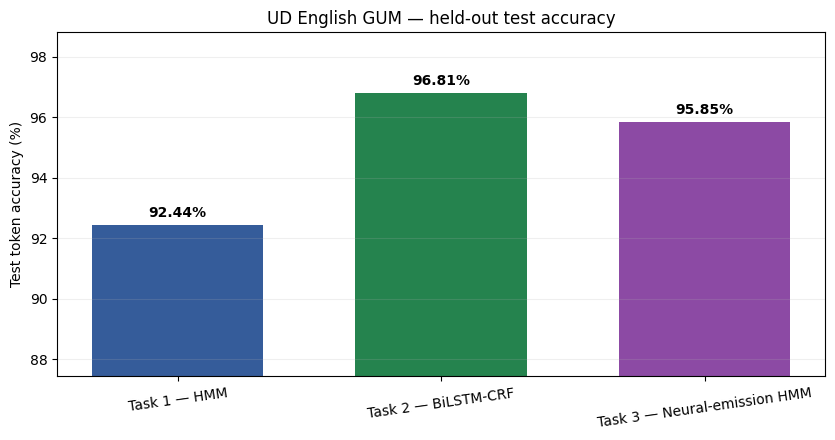

## Qualitative test examples

### Example 1 — test sentence 539

The count-based HMM is strongest on this sentence.  


Position,Token,Gold UPOS,Task 1 HMM,Task 2 BiLSTM-CRF,Task 3 Neural-HMM
1,Falling,PROPN,PROPN,VERB,VERB


### Example 2 — test sentence 663

The systems make different token-level errors despite similar sentence accuracy.  


Position,Token,Gold UPOS,Task 1 HMM,Task 2 BiLSTM-CRF,Task 3 Neural-HMM
1,Interview,NOUN,PROPN,NOUN,NOUN


### Example 3 — test sentence 728

The systems make different token-level errors despite similar sentence accuracy.  


Position,Token,Gold UPOS,Task 1 HMM,Task 2 BiLSTM-CRF,Task 3 Neural-HMM
1,Interview,NOUN,PROPN,NOUN,NOUN


## Result interpretation
- **Best held-out result:** Task 2 — BiLSTM-CRF.
- Task 3 changes Task 1 by **+3.416% absolute**, isolating the effect of contextual neural emissions while retaining the HMM transitions and Viterbi decoder.
- Task 3 changes Task 2 by **-0.954% absolute**, reflecting the effect of replacing learned CRF transitions with the fixed HMM transition model.
- The hybrid closes part of the Task 1→Task 2 gap, indicating that contextual emissions help while jointly learned CRF transitions still contribute.

In [28]:
#@title Evaluation and comparison

test_gold = [list(tags) for _, tags in test]
total_test_tokens = sum(len(tags) for tags in test_gold)

task1_test_accuracy, task1_predictions, task1_eval_gold = evaluate_hmm(
    hmm, test
)
task2_test = evaluate_crf(task2_model, test_loader)
task2_test_accuracy = task2_test["accuracy"]
task2_predictions = task2_test["predictions"]

task3_softmax_test = evaluate_softmax(task3_model, test_loader)
task3_test_accuracy, task3_predictions, task3_eval_gold = evaluate_neural_hmm(
    task3_model, test_loader, hmm, temperature
)

# Integrity checks: all systems must be evaluated against exactly the same
# official test labels, with one prediction per gold token.
assert task1_eval_gold == test_gold
assert task2_test["gold"] == test_gold
assert task3_softmax_test["gold"] == test_gold
assert task3_eval_gold == test_gold
for system_name, predictions in {
    "Task 1": task1_predictions,
    "Task 2": task2_predictions,
    "Task 3": task3_predictions,
}.items():
    assert len(predictions) == len(test_gold), f"{system_name}: sentence-count mismatch"
    assert all(len(pred) == len(gold) for pred, gold in zip(predictions, test_gold)), (
        f"{system_name}: token-count mismatch"
    )


def correct_token_count(gold_sequences, predicted_sequences):
    return sum(
        gold_tag == predicted_tag
        for gold, prediction in zip(gold_sequences, predicted_sequences)
        for gold_tag, predicted_tag in zip(gold, prediction)
    )


comparison = pd.DataFrame([
    {
        "Task": "Task 1 — HMM",
        "Correct tokens": correct_token_count(test_gold, task1_predictions),
        "Total test tokens": total_test_tokens,
        "Test token accuracy": task1_test_accuracy,
    },
    {
        "Task": "Task 2 — BiLSTM-CRF",
        "Correct tokens": correct_token_count(test_gold, task2_predictions),
        "Total test tokens": total_test_tokens,
        "Test token accuracy": task2_test_accuracy,
    },
    {
        "Task": "Task 3 — Neural-emission HMM",
        "Correct tokens": correct_token_count(test_gold, task3_predictions),
        "Total test tokens": total_test_tokens,
        "Test token accuracy": task3_test_accuracy,
    },
])
comparison["Test accuracy (%)"] = 100 * comparison["Test token accuracy"]
comparison.to_csv(OUTPUT_DIR / "task_comparison.csv", index=False)

display(Markdown("## Final test results"))
display(
    comparison[["Task", "Correct tokens", "Total test tokens", "Test accuracy (%)"]]
    .style
    .hide(axis="index")
    .format({
        "Correct tokens": "{:,}",
        "Total test tokens": "{:,}",
        "Test accuracy (%)": "{:.3f}",
    })
    .set_properties(**{"text-align": "center", "padding": "5px 12px"})
    .set_properties(subset=["Task"], **{"text-align": "left"})
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "center"), ("background-color", "#edf2f7")]},
        {"selector": "caption", "props": [("caption-side", "top"), ("font-weight", "bold")]},
    ])
)

fig, ax = plt.subplots(figsize=(8.5, 4.5))
bars = ax.bar(
    comparison["Task"], comparison["Test accuracy (%)"],
    color=["#355C9A", "#25834E", "#8C4AA4"], width=0.65,
)
ax.set_ylabel("Test token accuracy (%)")
ax.set_title("UD English GUM — held-out test accuracy")
ax.set_ylim(
    max(0, comparison["Test accuracy (%)"].min() - 5),
    min(100, comparison["Test accuracy (%)"].max() + 2),
)
ax.tick_params(axis="x", rotation=8)
ax.grid(axis="y", alpha=0.2)
for bar, value in zip(bars, comparison["Test accuracy (%)"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2, value + 0.15,
        f"{value:.2f}%", ha="center", va="bottom", fontweight="bold",
    )
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "task_comparison.png", dpi=180, bbox_inches="tight")
plt.show()


# --------------------------- Qualitative examples ---------------------------
def sentence_accuracy(gold, prediction):
    return sum(g == p for g, p in zip(gold, prediction)) / len(gold)


def select_qualitative_indices(limit=3, max_tokens=35):
    """Select short, informative test sentences without manually cherry-picking."""
    candidates = []
    for index, ((tokens, gold), pred1, pred2, pred3) in enumerate(zip(
        test, task1_predictions, task2_predictions, task3_predictions
    )):
        if len(tokens) > max_tokens:
            continue
        accuracies = [
            sentence_accuracy(gold, pred1),
            sentence_accuracy(gold, pred2),
            sentence_accuracy(gold, pred3),
        ]
        if min(accuracies) == 1.0:
            continue
        disagreement = max(accuracies) - min(accuracies)
        error_rate = 1.0 - min(accuracies)
        candidates.append((disagreement, error_rate, -index, index))
    candidates.sort(reverse=True)
    return [item[-1] for item in candidates[:limit]]


def qualitative_reason(acc1, acc2, acc3):
    if acc3 > acc2:
        return "Task 3 improves over the neural CRF on this sentence."
    if acc2 > acc3:
        return "Task 2 outperforms the neural-emission HMM on this sentence."
    if acc1 > max(acc2, acc3):
        return "The count-based HMM is strongest on this sentence."
    return "The systems make different token-level errors despite similar sentence accuracy."


display(Markdown("## Qualitative test examples"))
qualitative_rows = []
selected_indices = select_qualitative_indices()
assert selected_indices, "No suitable qualitative examples found."

for example_number, index in enumerate(selected_indices, start=1):
    tokens, gold = test[index]
    pred1 = task1_predictions[index]
    pred2 = task2_predictions[index]
    pred3 = task3_predictions[index]
    acc1 = sentence_accuracy(gold, pred1)
    acc2 = sentence_accuracy(gold, pred2)
    acc3 = sentence_accuracy(gold, pred3)

    frame = pd.DataFrame({
        "Position": range(1, len(tokens) + 1),
        "Token": tokens,
        "Gold UPOS": gold,
        "Task 1 HMM": pred1,
        "Task 2 BiLSTM-CRF": pred2,
        "Task 3 Neural-HMM": pred3,
    })
    qualitative_rows.append(frame.assign(sentence_index=index))

    display(Markdown(
        f"### Example {example_number} — test sentence {index}\n\n"
        f"{qualitative_reason(acc1, acc2, acc3)}  \n"

    ))

    prediction_columns = ["Task 1 HMM", "Task 2 BiLSTM-CRF", "Task 3 Neural-HMM"]

    def highlight_errors(row):
        styles = pd.Series("", index=row.index)
        for column in prediction_columns:
            if row[column] != row["Gold UPOS"]:
                styles[column] = "background-color: #fde2e2; color: #8b1e1e; font-weight: 600"
        return styles

    styled = (
        frame.style
        .hide(axis="index")
        .apply(highlight_errors, axis=1)
        .set_properties(**{
            "text-align": "center",
            "padding": "4px 9px",
            "white-space": "nowrap",
            "border": "1px solid #d9dee5",
        })
        .set_properties(subset=["Token"], **{"text-align": "left", "font-weight": "600"})
        .set_table_styles([
            {"selector": "table", "props": [("border-collapse", "collapse"), ("width", "auto")]},
            {"selector": "th", "props": [
                ("text-align", "center"), ("padding", "5px 9px"),
                ("background-color", "#edf2f7"), ("border", "1px solid #d9dee5"),
            ]},
        ])
    )
    display(styled)

pd.concat(qualitative_rows, ignore_index=True).to_csv(
    OUTPUT_DIR / "qualitative_examples.csv", index=False
)


# ------------------------------- Discussion -------------------------------
delta_31 = task3_test_accuracy - task1_test_accuracy
delta_32 = task3_test_accuracy - task2_test_accuracy
best_task = comparison.loc[comparison["Test token accuracy"].idxmax(), "Task"]

discussion = [
    "## Result interpretation",
    f"- **Best held-out result:** {best_task}.",
    f"- Task 3 changes Task 1 by **{delta_31:+.3%} absolute**, isolating the effect of contextual neural emissions while retaining the HMM transitions and Viterbi decoder.",
    f"- Task 3 changes Task 2 by **{delta_32:+.3%} absolute**, reflecting the effect of replacing learned CRF transitions with the fixed HMM transition model.",
]
if task3_test_accuracy <= task1_test_accuracy:
    discussion.append(
        "- The hybrid does not improve over the count-based HMM in this run; plausible causes include emission/transition scale mismatch, imperfect calibration, or strong lexical memorization by the HMM."
    )
elif task3_test_accuracy < task2_test_accuracy:
    discussion.append(
        "- The hybrid closes part of the Task 1→Task 2 gap, indicating that contextual emissions help while jointly learned CRF transitions still contribute."
    )
else:
    discussion.append(
        "- The hybrid matches or exceeds the CRF, suggesting that the count-based UPOS transition structure is sufficient once the contextual emissions are strong and calibrated."
    )
display(Markdown("\n".join(discussion)))


In [30]:
#@title save
predictions_path = OUTPUT_DIR / "test_predictions.jsonl"
with predictions_path.open("w", encoding="utf-8") as handle:
    for index, ((tokens, gold), pred1, pred2, pred3) in enumerate(zip(
        test, task1_predictions, task2_predictions, task3_predictions
    )):
        handle.write(json.dumps({
            "sentence_index": index,
            "tokens": tokens,
            "gold": gold,
            "task1_hmm": pred1,
            "task2_bilstm_crf": pred2,
            "task3_neural_hmm": pred3,
        }, ensure_ascii=False) + "\n")

results = {
    "dataset": DATASET_ID,
    "config": DATASET_CONFIG,
    "revision": UD_REVISION,
    "seed": SEED,
    "total_test_tokens": total_test_tokens,
    "glove_source": GLOVE_NAME,
    "glove_coverage": glove_coverage,
    "task1_test_token_accuracy": task1_test_accuracy,
    "task2_best_validation_accuracy": task2_best_validation,
    "task2_test_token_accuracy": task2_test_accuracy,
    "task3_best_validation_softmax_accuracy": task3_best_validation,
    "task3_temperature": temperature,
    "task3_independent_softmax_test_accuracy": task3_softmax_test["accuracy"],
    "task3_neural_hmm_test_token_accuracy": task3_test_accuracy,
}
with (OUTPUT_DIR / "results.json").open("w", encoding="utf-8") as handle:
    json.dump(results, handle, indent=2)

configuration = {
    "lambda": LAMBDA,
    "open_class_tags": OPEN_CLASS_TAGS,
    "batch_size": BATCH_SIZE,
    "max_epochs": MAX_EPOCHS,
    "patience": PATIENCE,
    "optimizer": "SGD",
    "momentum": MOMENTUM,
    "initial_learning_rate": LEARNING_RATE,
    "learning_rate_schedule": "lr0 / (1 + 0.05 * (epoch - 1))",
    "gradient_clip_norm": GRAD_CLIP,
    "word_embedding_dim": 100,
    "char_embedding_dim": 25,
    "char_lstm_hidden_per_direction": 25,
    "word_lstm_hidden_per_direction": 100,
    "dropout": 0.5,
}
with (OUTPUT_DIR / "configuration.json").open("w", encoding="utf-8") as handle:
    json.dump(configuration, handle, indent=2)

freeze = subprocess.check_output([sys.executable, "-m", "pip", "freeze"], text=True)
(OUTPUT_DIR / "environment_freeze.txt").write_text(freeze, encoding="utf-8")

archive_base = (Path("/content") if Path("/content").exists() else Path.cwd()) / "Project2_UD_English_GUM_outputs"
archive_path = shutil.make_archive(str(archive_base), "zip", root_dir=OUTPUT_DIR)
print("Saved results directory:", OUTPUT_DIR)
print("Download this archive:", archive_path)


Saved results directory: /content/project2_gum_outputs
Download this archive: /content/Project2_UD_English_GUM_outputs.zip


## Running tasks independently

- **Task 1 only:** run setup, data, and all Task 1 cells. No GPU is required.
- **Task 2 only:** run setup, data, shared neural data, and Task 2 cells. A GPU is strongly recommended.
- **Task 3:** it requires Task 1 transitions and the Task 2 encoder. Run those prerequisite cells first, or place their compatible checkpoints in `project2_gum_outputs/checkpoints/`, then run the Task 3 cells.
- **All tasks in sequence:** use **Runtime → Run all**.

Compatible checkpoints are reused automatically.
